# Task 5: Titanic survival (reference solution)

This is the finished version of every worked example in `03_ml/notes/task5_ex*.md`, with its real outputs. **Type your own version first** in `03_ml/titanic_model.ipynb`, then use this file to compare or to get unstuck.

It runs from `03_ml/examples/`, so the paths start with `../` (the notes, written for `03_ml/`, don't have that). Its charts and model files go to the same `03_ml/output/` and `03_ml/models/` folders as yours, and they come out identical.

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
)
from sklearn.model_selection import GridSearchCV, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree

## Exercise 1: X, y, split, and a baseline

In [2]:
df = pd.read_csv("../../02_data/data/titanic.csv")
features = ["pclass", "sex", "age", "sibsp", "parch", "fare", "embarked"]
X = df[features]
y = df["survived"]
print("X:", X.shape)
print("y:", y.shape)
display(X.head(3))

X: (891, 7)
y: (891,)


,pclass,sex,age,sibsp,parch,fare,embarked
0,3,male,22.0,1,0,7.2500,S
1,1,female,38.0,1,0,71.2833,C
2,3,female,26.0,0,0,7.9250,S


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Train:", X_train.shape, " Test:", X_test.shape)
print(f"Survival rate - train: {y_train.mean():.1%}, test: {y_test.mean():.1%}")
print("First 5 training rows:", X_train.index[:5].tolist())

Train: (712, 7)  Test: (179, 7)
Survival rate - train: 38.3%, test: 38.5%
First 5 training rows: [692, 481, 527, 855, 801]


In [4]:
_, _, _, y_test_random = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Without stratify, test survival rate: {y_test_random.mean():.1%}")

Without stratify, test survival rate: 41.3%


In [5]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
print("Predictions for 5 test passengers:", baseline.predict(X_test.head()))
print(f"Baseline accuracy on the test set: {baseline.score(X_test, y_test):.1%}")

Predictions for 5 test passengers: [0 0 0 0 0]
Baseline accuracy on the test set: 61.5%


## Exercise 1 answers
- **X** = 7 features (`pclass`, `sex`, `age`, `sibsp`, `parch`, `fare`, `embarked`); **y** = `survived`.
- **Left out:** `alive` (it is the answer: leakage), `class` and `embark_town` (copies), `who`, `adult_male` and `alone` (calculated from other features), `deck` (77% missing).
- **Split:** 712 training rows and 179 test rows (80/20). `stratify=y` keeps the survival rate equal: 38.3% vs 38.5%. Without it, the test set gets 41.3%.
- **Baseline:** always predicting "died" scores **61.5%**, so a real model must beat that to have learned anything.

## Exercise 2: Logistic regression

In [6]:
def simple_features(X):
    """Only the complete number columns, plus sex as 1/0."""
    table = X[["pclass", "sibsp", "parch", "fare"]].copy()
    table["is_male"] = (X["sex"] == "male").astype(int)
    return table


X_train_simple = simple_features(X_train)
X_test_simple = simple_features(X_test)
display(X_train_simple.head(3))

,pclass,sibsp,parch,fare,is_male
692,3,0,0,56.4958,1
481,2,0,0,0.0000,1
527,1,0,0,221.7792,1


In [7]:
model = LogisticRegression()
model.fit(X_train_simple, y_train)
print(f"Train accuracy: {model.score(X_train_simple, y_train):.1%}")
print(f"Test accuracy:  {model.score(X_test_simple, y_test):.1%}")

Train accuracy: 79.5%


Test accuracy:  81.0%


In [8]:
first5 = X_test_simple.head()
display(first5.assign(
    actual=y_test.head(),
    predicted=model.predict(first5),
    chance=model.predict_proba(first5)[:, 1].round(2),
))

,pclass,sibsp,parch,fare,is_male,actual,predicted,chance
565,3,2,0,24.1500,1,0,0,0.09
160,3,0,1,16.1000,1,0,0,0.10
553,3,0,0,7.2250,1,1,0,0.11
860,3,2,0,14.1083,1,0,0,0.08
241,3,1,0,15.5000,0,1,1,0.60


In [9]:
coefs = pd.Series(model.coef_[0], index=X_train_simple.columns).sort_values()
print(coefs.round(2))
print("Intercept:", model.intercept_.round(2))

is_male   -2.62
pclass    -0.82
sibsp     -0.18
parch     -0.09
fare       0.00
dtype: float64
Intercept: [2.98]


In [10]:
passenger = first5.loc[241]
z = model.intercept_[0] + (passenger * model.coef_[0]).sum()
print(passenger.tolist())
print(f"Score z = {z:.2f}")
print(f"Chance  = {1 / (1 + np.exp(-z)):.2f}")

[3.0, 1.0, 0.0, 15.5, 0.0]
Score z = 0.39
Chance  = 0.60


## Exercise 2 answers
- **Features:** `pclass`, `sibsp`, `parch`, `fare` and `is_male`, built by one function so training and test tables match.
- **Accuracy:** train 79.5%, test **81.0%**, which is 19.5 points above the baseline. The two scores are close, so the model learned general patterns.
- **First 5 test passengers:** 4 of 5 right. The woman in row 241 gets a 60% chance, so she is predicted to survive, and she did.
- **Biggest push:** `is_male` (−2.62), then `pclass` (−0.82 per class). The weights can't be compared yet because the columns use different units (fare is per pound).
- **How it predicts:** a weighted sum of the features, squashed into 0–1 by the sigmoid function. Above 0.5 → "survived".

## Exercise 3: Confusion matrix, precision and recall

In [11]:
predictions = model.predict(X_test_simple)
cm = confusion_matrix(y_test, predictions)
print(cm)

[[99 11]
 [23 46]]


In [12]:
print(classification_report(y_test, predictions, target_names=["died", "survived"]))

              precision    recall  f1-score   support

        died       0.81      0.90      0.85       110
    survived       0.81      0.67      0.73        69

    accuracy                           0.81       179
   macro avg       0.81      0.78      0.79       179
weighted avg       0.81      0.81      0.81       179



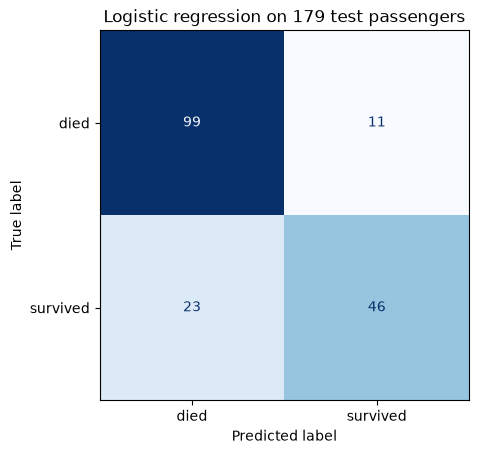

In [13]:
output_dir = Path("../output")
output_dir.mkdir(exist_ok=True)

ConfusionMatrixDisplay.from_predictions(
    y_test, predictions, display_labels=["died", "survived"],
    cmap="Blues", colorbar=False,
)
plt.title("Logistic regression on 179 test passengers")
plt.savefig(output_dir / "confusion_matrix.png", bbox_inches="tight")
plt.show()

In [14]:
chance = model.predict_proba(X_test_simple)[:, 1]
for threshold in [0.3, 0.4, 0.5, 0.6, 0.7]:
    pred = (chance >= threshold).astype(int)
    print(f"threshold {threshold}: "
          f"precision {precision_score(y_test, pred):.2f}, "
          f"recall {recall_score(y_test, pred):.2f}, "
          f"predicted survivors {pred.sum()}")

threshold 0.3: precision 0.62, recall 0.81, predicted survivors 91
threshold 0.4: precision 0.65, recall 0.77, predicted survivors 82
threshold 0.5: precision 0.81, recall 0.67, predicted survivors 57
threshold 0.6: precision 0.86, recall 0.55, predicted survivors 44
threshold 0.7: precision 0.94, recall 0.46, predicted survivors 34


## Exercise 3 answers
- **Confusion matrix** `[[99 11] [23 46]]`: 99 deaths predicted correctly, 11 false alarms (predicted survived, died), 23 survivors missed (predicted died, survived), 46 survivors found.
- **Survived:** precision **0.81** (when it says "survived", it's right 81% of the time), recall **0.67** (it finds only 2 in 3 survivors).
- **Accuracy hides this:** 81% sounds good, but the model misses a third of the survivors.
- **The cut-off is a trade-off:** 0.3 gives recall 0.81 but precision 0.62; 0.7 gives precision 0.94 but recall 0.46. Choose it from the cost of each mistake.

## Exercise 4: Data leakage

In [15]:
alive = (df["alive"] == "yes").astype(int)
X_train_leak = X_train_simple.assign(alive=alive)
X_test_leak = X_test_simple.assign(alive=alive)
leaky = LogisticRegression().fit(X_train_leak, y_train)
print(f"Test accuracy with 'alive': {leaky.score(X_test_leak, y_test):.1%}")
print(pd.Series(leaky.coef_[0], index=X_train_leak.columns).round(2))

Test accuracy with 'alive': 100.0%
pclass    -0.35
sibsp     -0.08
parch     -0.01
fare       0.00
is_male   -1.05
alive      7.18
dtype: float64


In [16]:
print("Median age, all 891 rows:  ", df["age"].median())
print("Median age, training rows: ", X_train["age"].median())

Median age, all 891 rows:   28.0
Median age, training rows:  28.5


## Exercise 4 answers
- **Adding `alive` gives 100% test accuracy**, and the model is useless: `alive` is the answer in words (weight 7.18 vs −1.05 for `is_male`), and it's unknown for a new passenger. A score that looks too good is a sign of leakage.
- **Two kinds of leakage:**
  - **(a) A feature that is the answer**, or that is only known after the event (`alive`, `cancellation_date`). Ask: would I know this value when I need the prediction?
  - **(b) Test data used in preparation**, such as filling missing ages with the median of all 891 rows (28.0) instead of the training rows only (28.5).
- **The fix for (b):** fit every preparation step on the training set only, then apply it to the test set. A `Pipeline` does this automatically (Exercise 5).

## Exercise 5: Pipelines

In [17]:
numeric = ["pclass", "age", "sibsp", "parch", "fare"]
categorical = ["sex", "embarked"]

numeric_steps = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])
categorical_steps = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])
preprocess = ColumnTransformer([
    ("num", numeric_steps, numeric),
    ("cat", categorical_steps, categorical),
])

In [18]:
pipe = Pipeline([("prep", preprocess), ("model", LogisticRegression())])
pipe.fit(X_train, y_train)
print(f"Train accuracy: {pipe.score(X_train, y_train):.1%}")
print(f"Test accuracy:  {pipe.score(X_test, y_test):.1%}")

Train accuracy: 80.8%
Test accuracy:  80.4%


In [19]:
prep = pipe.named_steps["prep"]
names = prep.get_feature_names_out()
print(names)
medians = prep.named_transformers_["num"].named_steps["impute"].statistics_
print("Learned medians:", dict(zip(numeric, medians, strict=True)))

['num__pclass' 'num__age' 'num__sibsp' 'num__parch' 'num__fare'
 'cat__sex_female' 'cat__sex_male' 'cat__embarked_C' 'cat__embarked_Q'
 'cat__embarked_S']
Learned medians: {'pclass': np.float64(3.0), 'age': np.float64(28.5), 'sibsp': np.float64(0.0), 'parch': np.float64(0.0), 'fare': np.float64(14.4542)}


In [20]:
sample = X_train.head(3)
display(sample)
display(
    pd.DataFrame(prep.transform(sample), columns=names, index=sample.index).round(2)
)

,pclass,sex,age,sibsp,parch,fare,embarked
692,3,male,NaN,0,0,56.4958,S
481,2,male,NaN,0,0,0.0000,S
527,1,male,NaN,0,0,221.7792,S


,num__pclass,num__age,num__sibsp,num__parch,num__fare,cat__sex_female,cat__sex_male,cat__embarked_C,cat__embarked_Q,cat__embarked_S
692,0.83,-0.08,-0.47,-0.47,0.51,0.0,1.0,0.0,0.0,1.0
481,-0.37,-0.08,-0.47,-0.47,-0.66,0.0,1.0,0.0,0.0,1.0
527,-1.57,-0.08,-0.47,-0.47,3.96,0.0,1.0,0.0,0.0,1.0


In [21]:
coefs = pd.Series(pipe.named_steps["model"].coef_[0], index=names).sort_values()
print(coefs.round(2))

cat__sex_male     -1.32
num__pclass       -0.92
num__age          -0.50
cat__embarked_S   -0.36
num__sibsp        -0.26
num__parch        -0.07
cat__embarked_C    0.03
num__fare          0.10
cat__embarked_Q    0.30
cat__sex_female    1.30
dtype: float64


## Exercise 5 answers
- **Pipeline:** numbers → fill with the median → scale; text → fill with the most common value → one-hot. Then logistic regression. It's fitted on the **raw** `X_train`.
- **Accuracy:** train 80.8%, test **80.4%** (144 of 179), 1 passenger fewer than Exercise 2, so the 179-row test set can't tell these models apart.
- **Inside:** 7 columns become 10 after one-hot (`sex` → 2, `embarked` → 3). The learned medians are `[3, 28.5, 0, 0, 14.4542]`. The **28.5** (not 28.0) proves it only learned from the training rows, so no leakage.
- **Scaled weights are comparable:** sex is strongest (±1.3), then class (−0.92) and age (−0.50); fare adds little (+0.10) once class is known.

## Exercise 6: Trees and overfitting

In [22]:
def make_model(estimator):
    """The Exercise 5 cleaning steps, followed by any model."""
    return Pipeline([("prep", clone(preprocess)), ("model", estimator)])


tree = make_model(DecisionTreeClassifier(random_state=42))
tree.fit(X_train, y_train)
print(f"Train accuracy: {tree.score(X_train, y_train):.1%}")
print(f"Test accuracy:  {tree.score(X_test, y_test):.1%}")

Train accuracy: 98.3%
Test accuracy:  81.6%


In [23]:
rows = []
for depth in [2, 3, 4, 5, 6, 8]:
    m = make_model(DecisionTreeClassifier(max_depth=depth, random_state=42))
    m.fit(X_train, y_train)
    rows.append({"max_depth": depth,
                 "train": m.score(X_train, y_train),
                 "test": m.score(X_test, y_test)})
display(pd.DataFrame(rows).round(3))

,max_depth,train,test
0,2,0.805,0.760
1,3,0.833,0.793
2,4,0.841,0.793
3,5,0.865,0.765
4,6,0.886,0.804
5,8,0.917,0.816


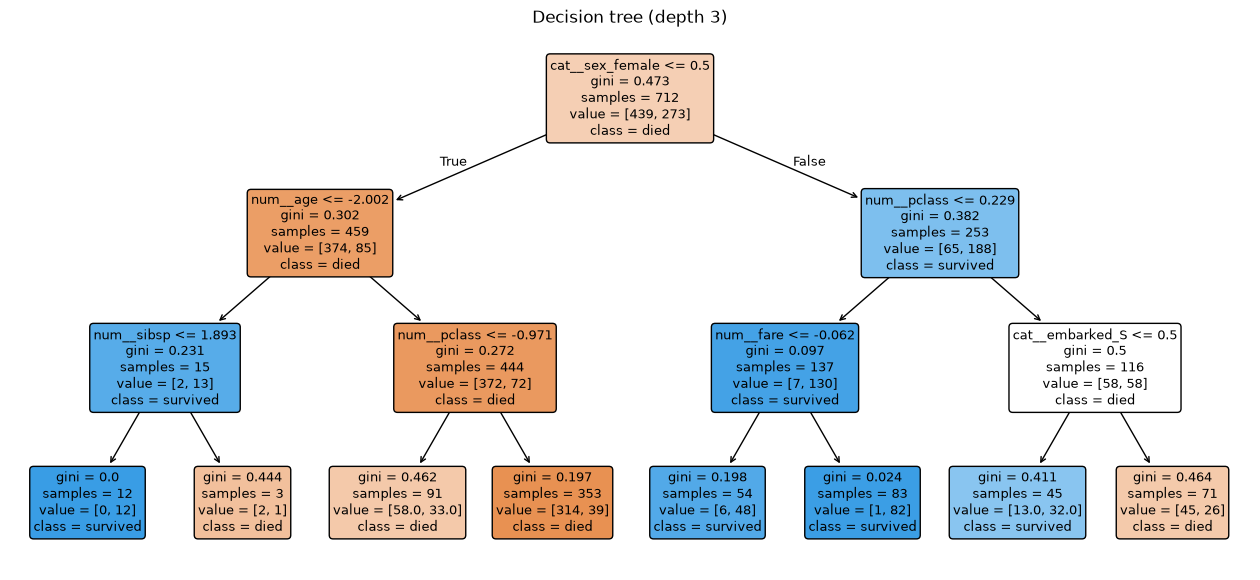

In [24]:
small_tree = make_model(DecisionTreeClassifier(max_depth=3, random_state=42))
small_tree.fit(X_train, y_train)
plt.figure(figsize=(16, 7))
plot_tree(
    small_tree.named_steps["model"],
    feature_names=small_tree.named_steps["prep"].get_feature_names_out(),
    class_names=["died", "survived"],
    filled=True, rounded=True, fontsize=9,
)
plt.title("Decision tree (depth 3)")
plt.savefig(output_dir / "decision_tree.png", bbox_inches="tight")
plt.show()

In [25]:
forest = make_model(RandomForestClassifier(random_state=42))
forest.fit(X_train, y_train)
print(f"Train accuracy: {forest.score(X_train, y_train):.1%}")
print(f"Test accuracy:  {forest.score(X_test, y_test):.1%}")
importance = pd.Series(
    forest.named_steps["model"].feature_importances_,
    index=forest.named_steps["prep"].get_feature_names_out(),
).sort_values(ascending=False)
print(importance.round(3))

Train accuracy: 98.3%
Test accuracy:  81.6%
num__fare          0.259
num__age           0.244
cat__sex_male      0.159
cat__sex_female    0.131
num__pclass        0.085
num__sibsp         0.047
num__parch         0.040
cat__embarked_S    0.014
cat__embarked_C    0.013
cat__embarked_Q    0.008
dtype: float64


## Exercise 6 answers
- **Unlimited tree:** train 98.3%, test 81.6%. The big gap is **overfitting**: 23 levels and 152 leaves memorise the training passengers.
- **Depth limits:** the training score rises with depth (0.805 at depth 2 → 0.917 at depth 8), but the test score jumps around (0.760–0.816), so one small test set can't choose the depth.
- **Depth-3 tree:** first question "is male?", then age ≤ 3.5 for men and class for women. It found "women and children first" by itself. Its thresholds are in scaled units (−2.0 = 3.5 years); trees don't need scaling.
- **Random forest:** 100 voting trees, train 98.3% / test 81.6%. Importances: fare 0.26, age 0.24, sex 0.29 in total (0.16 + 0.13). Impurity importance favours columns with many values, so read it with care.

## Exercise 7: Cross-validation and tuning

In [26]:
candidates = {
    "logistic regression": LogisticRegression(),
    "tree (depth 3)": DecisionTreeClassifier(max_depth=3, random_state=42),
    "tree (no limit)": DecisionTreeClassifier(random_state=42),
    "random forest": RandomForestClassifier(random_state=42),
}
for name, estimator in candidates.items():
    scores = cross_val_score(make_model(estimator), X_train, y_train, cv=5)
    print(f"{name:<20} {scores.mean():.1%} ± {scores.std():.1%}",
          f"  folds: {scores.round(3)}")

logistic regression  79.6% ± 1.9%   folds: [0.79  0.762 0.803 0.817 0.81 ]
tree (depth 3)       80.8% ± 3.1%   folds: [0.811 0.748 0.831 0.831 0.817]


tree (no limit)      77.8% ± 3.6%   folds: [0.762 0.72  0.789 0.789 0.831]


random forest        79.1% ± 4.5%   folds: [0.79  0.713 0.838 0.831 0.782]


In [27]:
grid = GridSearchCV(
    make_model(RandomForestClassifier(random_state=42)),
    param_grid={
        "model__max_depth": [3, 5, 7, None],
        "model__min_samples_leaf": [1, 3, 5],
    },
    cv=5,
)
grid.fit(X_train, y_train)
print("Best settings:", grid.best_params_)
print(f"Best CV accuracy: {grid.best_score_:.1%}")

Best settings: {'model__max_depth': 5, 'model__min_samples_leaf': 5}
Best CV accuracy: 82.9%


In [28]:
results = pd.DataFrame(grid.cv_results_)
display(results[["param_model__max_depth", "param_model__min_samples_leaf",
                 "mean_test_score", "std_test_score", "rank_test_score"]]
        .sort_values("rank_test_score").head(5).round(3))

,param_model__max_depth,param_model__min_samples_leaf,mean_test_score,std_test_score,rank_test_score
5,5,5,0.829,0.028,1
3,5,1,0.823,0.031,2
11,None,5,0.823,0.025,3
10,None,3,0.822,0.025,4
4,5,3,0.817,0.027,5


In [29]:
print(f"Test accuracy (once, at the end): {grid.score(X_test, y_test):.1%}")

Test accuracy (once, at the end): 79.9%


## Exercise 7 answers
- **5-fold cross-validation** (training set only): logistic regression 79.6% ± 1.9%, depth-3 tree 80.8% ± 3.1%, unlimited tree **77.8%** ± 3.6% (the overfitting shows here; its 81.6% test score was luck), random forest 79.1% ± 4.5%.
- **Grid search** (12 settings × 5 folds = 60 fits): best `max_depth=5`, `min_samples_leaf=5`, CV **82.9%**. Limiting the trees beats the default forest by about 4 points.
- **Test score, once:** **79.9%** (143 of 179). It's lower than CV because the test set is small (1 passenger = 0.56 points, so the gap is about 5 passengers) and the best of 12 settings is slightly flattered by luck.
- **Rule:** choose models and settings with cross-validation; touch the test set once, at the end.

## Exercise 8: Save and use the model

In [30]:
models_dir = Path("../models")
models_dir.mkdir(exist_ok=True)
model_path = models_dir / "titanic_model.joblib"
joblib.dump(grid.best_estimator_, model_path)
print(f"Saved {model_path.name} ({model_path.stat().st_size / 1024:.0f} KB)")

Saved titanic_model.joblib (350 KB)


In [31]:
loaded = joblib.load(model_path)
same = (loaded.predict(X_test) == grid.predict(X_test)).all()
print("Same predictions as before:", same)

Same predictions as before: True


In [32]:
new_passengers = pd.DataFrame([
    {"pclass": 1, "sex": "female", "age": 17, "sibsp": 1, "parch": 1,
     "fare": 100.0, "embarked": "S"},
    {"pclass": 3, "sex": "male", "age": 20, "sibsp": 0, "parch": 0,
     "fare": 8.05, "embarked": "S"},
    {"pclass": 2, "sex": "male", "age": 5, "sibsp": 1, "parch": 1,
     "fare": 26.0, "embarked": "S"},
    {"pclass": 3, "sex": "female", "age": None, "sibsp": 0, "parch": 0,
     "fare": 7.75, "embarked": "Q"},
])
display(new_passengers.assign(
    prediction=loaded.predict(new_passengers),
    survival_chance=loaded.predict_proba(new_passengers)[:, 1].round(2),
))

,pclass,sex,age,sibsp,parch,fare,embarked,prediction,survival_chance
0,1,female,17.0,1,1,100.00,S,1,0.94
1,3,male,20.0,0,0,8.05,S,0,0.11
2,2,male,5.0,1,1,26.00,S,0,0.46
3,3,female,NaN,0,0,7.75,Q,1,0.76


In [33]:
request = {"pclass": 2, "sex": "female", "age": 30, "sibsp": 0, "parch": 0,
           "fare": 13.0, "embarked": "X"}
chance = loaded.predict_proba(pd.DataFrame([request]))[0, 1]
print(f"Survival chance: {chance:.0%}")

Survival chance: 84%


## Exercise 8 answers
- **Saved** the tuned pipeline (cleaning + random forest) to `models/titanic_model.joblib` (about 350 KB). Running the notebook rebuilds it.
- **Loaded** it back: the same predictions on all 179 test passengers. Only load model files you trust, with the same scikit-learn version.
- **New passengers:** 1st-class girl (17) **0.94**, 3rd-class man (20) **0.11**, 2nd-class boy (5) **0.46** (the training set's 8 second-class boys were all 3 or under, so the model never saw one like him), 3rd-class woman with no age **0.76** (the pipeline filled the age itself).
- **API preview:** dict → `pd.DataFrame([request])` → `predict_proba` is exactly what the FastAPI `/predict` endpoint will do in Phase 4. An unknown port (`"X"`) doesn't crash the model, but the API should validate input first (Pydantic).